# Buổi B3: Hồi quy nhiều biến, cho máy xem cả tờ phiếu

**Hiện trường.** Ở B2, mô hình chỉ nhìn **BMI** và đoán điểm tiến triển với R² khoảng 0,23: sai trung bình 52 điểm. Chị Hạnh nhớ rằng hồ sơ bệnh nhân còn **chín chỉ số nữa** (huyết áp, các chỉ số máu...). Chị hỏi: *"Cho máy xem hết thì có đoán tốt hơn không? Và chỉ số nào quan trọng nhất?"*

**Câu hỏi của buổi này:** *thêm cột đề thì mô hình tốt lên bao nhiêu, đọc các hệ số thế nào, và có bẫy nào không?*

**Mindset của người làm dữ liệu:** thêm thông tin thường giúp, nhưng **không phải cột nào cũng góp phần như nhau**, và các cột có thể *giẫm chân nhau*. Luôn kiểm tra trên tập thi, và nghi ngờ mọi câu "chỉ số này quan trọng nhất" cho đến khi kiểm chứng.

**Lưu ý:** dữ liệu mẫu để học, không dùng để chẩn đoán. Buổi này dùng lại cú pháp từ A1 đến B2 mà không giải thích lại.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Từ một ô đến nhiều ô: đường thẳng thành mặt phẳng |
| Chặng 2 | Dựng X nhiều cột, và quy tắc "cùng tên, cùng thứ tự" |
| Chặng 3 | Thêm từng cột: mỗi cột góp thêm bao nhiêu? |
| Chặng 4 | Đọc mười hệ số: "giữ các biến khác không đổi" |
| Chặng 5 | Cái bẫy khi hai cột sinh đôi: đa cộng tuyến |
| Chặng 6 | Phán quyết bằng quyết định thật: chọn 10 người theo dõi |

## Chặng 1: Từ một ô đến nhiều ô, đường thẳng thành mặt phẳng

**Câu hỏi:** khi có hai cột đề, mô hình trông thế nào?

Với một cột, mô hình là **đường thẳng** y = a + b·x. Với hai cột, nó thành **mặt phẳng** y = a + b₁·x₁ + b₂·x₂: mỗi cột có **độ dốc riêng**. Với mười cột thì có mười độ dốc (không vẽ được, nhưng cùng ý tưởng). Ta vẽ trường hợp hai cột (BMI và chỉ số `s5`) cho dễ hình dung.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
patients = load_diabetes(as_frame=True, scaled=False).frame
two = patients[["bmi", "s5"]]
plane = LinearRegression().fit(two, patients["target"])
print("intercept:", round(plane.intercept_, 1), "| coef (bmi, s5):", plane.coef_.round(1))

intercept: -300.0 | coef (bmi, s5): [ 7.3 56.1]


**Giải thích từng dòng**

- `from ... import ... (bốn dòng)`: (đã học) bộ đồ nghề quen thuộc.
- `two = patients[["bmi", "s5"]]`: (đã học ở B1) X **hai cột**: hai cặp ngoặc vuông với danh sách hai tên cột. Cùng quy tắc, chỉ dài hơn.
- `plane = LinearRegression().fit(two, patients["target"])`: (đã học) cùng một dòng `fit`; máy tự thấy có 2 cột và học 2 độ dốc. **Không cần đổi gì trong code.** Ở đây ta học trên toàn bộ dữ liệu chỉ để vẽ hình minh họa.
- `plane.coef_.round(1)`: `coef_` giờ là mảng **hai phần tử**, theo đúng thứ tự cột `(bmi, s5)`.

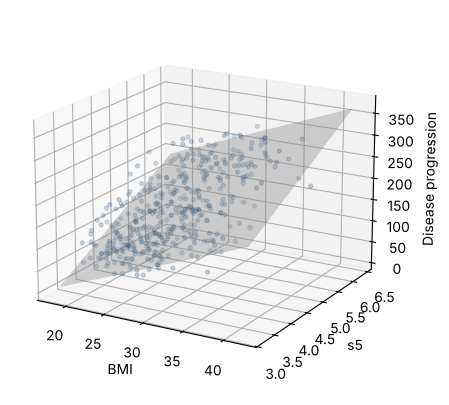

In [3]:
# 3D picture: just run it, no need to read the code line by line.
ax = plt.figure(figsize=(7, 5)).add_subplot(projection="3d")
ax.scatter(two["bmi"], two["s5"], patients["target"], color=BLUE, s=8, alpha=0.5)
gx, gy = np.meshgrid(np.linspace(18, 42, 10), np.linspace(3.2, 6.4, 10))
gz = plane.intercept_ + plane.coef_[0] * gx + plane.coef_[1] * gy
ax.plot_surface(gx, gy, gz, color=GRAY, alpha=0.35)
ax.set_xlabel("BMI"); ax.set_ylabel("s5"); ax.set_zlabel("Disease progression")
ax.view_init(elev=18, azim=-60)
plt.show()

**Cách đọc**

- **Con số:** `coef_` khoảng **(7,3 ; 56,1)**: ở mặt phẳng này, BMI tăng 1 đơn vị (giữ `s5` cố định) thì điểm dự đoán tăng khoảng 7; `s5` tăng 1 đơn vị (giữ BMI cố định) thì điểm dự đoán tăng khoảng 56.
- **Bức tranh:** đám chấm xanh tạo thành một **đám mây dốc lên** theo cả hai hướng; tấm kính xám là mặt phẳng ôm đám mây ấy. Thay vì *đường* ôm đám mây phẳng (B1), giờ là *tấm kính* ôm đám mây trong không gian.
- **Chữ quan trọng: "giữ cố định".** Mỗi độ dốc trả lời: *"nếu **chỉ** cột này tăng 1 đơn vị, **còn các cột khác giữ nguyên**, thì đáp án đổi bao nhiêu?"* Ta sẽ dùng cách đọc này mãi mãi.

**Mang về chặng 1:** hồi quy nhiều biến là *mặt phẳng* (nhiều chiều) y = a + b₁x₁ + b₂x₂ + ... Mỗi cột có **một độ dốc riêng**, đọc là "đổi bao nhiêu khi cột đó tăng 1, các cột khác giữ nguyên". Code **không đổi** so với một cột.

## Chặng 2: Dựng X nhiều cột, và quy tắc "cùng tên, cùng thứ tự"

**Câu hỏi:** làm sao đưa cả mười cột vào, và máy đòi gì ở dữ liệu mới?

In [4]:
X = patients.drop(columns="target")
y = patients["target"]
print("X shape:", X.shape, "| columns:", X.columns.tolist())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
full = LinearRegression().fit(X_train, y_train)
print("Columns the model was trained on:", full.feature_names_in_.tolist())

X shape: (442, 10) | columns: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Columns the model was trained on: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


**Giải thích từng dòng**

- `X = patients.drop(columns="target")`: (đã học `drop` ở A2) **cách nhanh nhất** dựng X nhiều cột: lấy **mọi cột trừ cột đáp án**. Không cần gõ từng tên.
- `X.columns.tolist()`: danh sách tên cột, đổi thành danh sách Python để in gọn.
- `train_test_split(X, y, test_size=0.2, random_state=42)`: (đã học) cùng cách chia và cùng hạt giống như B1, B2 nên cùng 89 bệnh nhân thi.
- `full.feature_names_in_`: **mới:** máy **nhớ tên các cột** mà nó đã học (chỉ có khi `fit` bằng bảng pandas có tên cột). Dấu gạch dưới cuối quen thuộc: chỉ có sau `fit`.

In [5]:
shuffled = X_test[["s5", "bmi"] + [c for c in X_test.columns if c not in ("s5", "bmi")]]
try:
    full.predict(shuffled)
except ValueError as err:
    print("ValueError:", str(err)[:120])

ValueError: The feature names should match those that were passed during fit.
Feature names must be in the same order as they were i


**Giải thích từng dòng**

- `shuffled = X_test[["s5", "bmi"] + [...]]`: cố tình **đảo thứ tự cột**: đưa `s5` và `bmi` lên đầu, các cột còn lại theo sau. Dấu `+` nối hai danh sách tên cột; danh sách thứ hai là list comprehension (đã học) lọc ra các cột còn lại, `not in (...)` nghĩa là "không nằm trong nhóm này".
- `full.predict(shuffled)`: đoán với bảng cột lộn thứ tự.

**Cách đọc**

- **Con số:** máy báo lỗi ngay: tên cột không **cùng thứ tự** với lúc học.
- **Bức tranh:** hãy hình dung mười độ dốc đã được **ghim cố định** vào từng ô của tờ phiếu: ô thứ nhất ghim độ dốc của `age`, ô thứ hai ghim độ dốc của `sex`... Nếu đảo thứ tự cột, độ dốc của `age` sẽ rơi nhầm vào cột `s5`, ra con số vô nghĩa. Sklearn chặn lỗi này giúp ta (nhờ nhớ tên cột).
- **Quy tắc:** dữ liệu mới đưa vào `predict` phải có **đúng cột, đúng tên, đúng thứ tự** như lúc `fit`. Nếu không có sẵn thứ tự, cách an toàn là `X_new[full.feature_names_in_]`.

**Mang về chặng 2:** X nhiều cột dựng nhanh bằng `drop(columns="target")`. Máy ghi nhớ tên và thứ tự cột lúc học (`feature_names_in_`); dữ liệu mới phải khớp.

## Chặng 3: Thêm từng cột, mỗi cột góp thêm bao nhiêu?

**Câu hỏi:** mười cột nghe nhiều. Mỗi cột thêm vào có đáng không?

Ta xếp các cột theo **độ liên quan với đáp án** (từ cao xuống thấp) rồi cho máy học với 1 cột, 2 cột, ... 10 cột. Mỗi mức ta lặp **30 lần chia sổ khác nhau** và lấy trung bình, để không bị phụ thuộc may rủi một lần chia (bài học A4).

In [6]:
order = X.corrwith(y).abs().sort_values(ascending=False).index.tolist()
rows = []
for k in range(1, 11):
    cols = order[:k]
    train_r2, test_r2, test_mae = [], [], []
    for seed in range(30):
        a, b, c, d = train_test_split(X[cols], y, test_size=0.2, random_state=seed)
        m = LinearRegression().fit(a, c)
        train_r2.append(m.score(a, c)); test_r2.append(m.score(b, d)); test_mae.append(mean_absolute_error(d, m.predict(b)))
    rows.append({"columns": k, "added": cols[-1], "train R2": np.mean(train_r2), "test R2": np.mean(test_r2), "test MAE": np.mean(test_mae)})
steps = pd.DataFrame(rows).round(3)
steps

,columns,added,train R2,test R2,test MAE
0,1,bmi,0.348,0.312,51.294
1,2,s5,0.463,0.428,46.558
2,3,bp,0.485,0.442,46.056
3,4,s4,0.487,0.440,46.119
4,5,s3,0.500,0.450,45.098
5,6,s6,0.500,0.449,45.178
6,7,s1,0.505,0.450,45.222
7,8,age,0.506,0.447,45.347
8,9,s2,0.508,0.446,45.439
9,10,sex,0.526,0.458,44.570


**Giải thích từng dòng**

- `order = X.corrwith(y).abs().sort_values(ascending=False).index.tolist()`: `X.corrwith(y)` tính tương quan của **từng cột X** với `y` (một dòng thay vì từng cặp); `.abs()` bỏ dấu; `.sort_values(ascending=False)` xếp giảm dần; `.index.tolist()` lấy **tên cột** theo thứ tự đó.
- `for k in range(1, 11):`: (đã học vòng lặp lồng nhau ở A4) vòng ngoài: dùng k cột đầu bảng.
- `cols = order[:k]`: lấy k tên đầu danh sách (phép cắt lát).
- `for seed in range(30):`: vòng trong: 30 cách chia khác nhau (mỗi hạt giống một cách).
- `train_r2.append(m.score(a, c)); ...`: ba danh sách gom R² train, R² test, MAE test qua 30 lần.
- `np.mean(...)`: (đã học) trung bình qua 30 lần chia.
- `rows.append({...}); steps = pd.DataFrame(rows).round(3)`: (đã học) gom thành bảng.

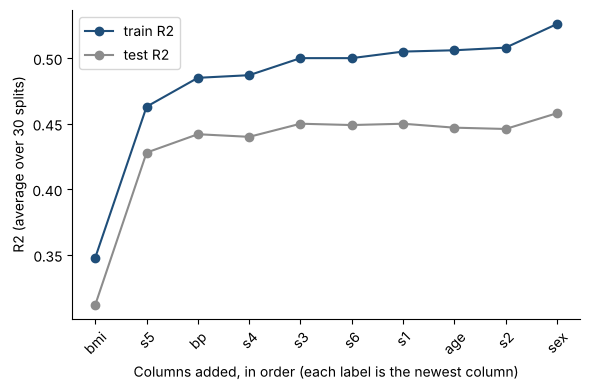

In [7]:
plt.plot(steps["columns"], steps["train R2"], "o-", color=BLUE, label="train R2")
plt.plot(steps["columns"], steps["test R2"], "o-", color=GRAY, label="test R2")
plt.xticks(steps["columns"], steps["added"], rotation=45)
plt.xlabel("Columns added, in order (each label is the newest column)")
plt.ylabel("R2 (average over 30 splits)")
plt.legend(); plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `plt.xticks(steps["columns"], steps["added"], rotation=45)`: (đã học `xticks` ở A2) nhãn trục ngang là **tên cột vừa thêm** ở mỗi mức; `rotation=45` nghiêng nhãn 45 độ cho khỏi chồng lên nhau.
- `plt.tight_layout()`: (đã học) tự chỉnh lề cho không bị cắt chữ.

**Cách đọc**

- **Con số:** với 1 cột (BMI), R² thi trung bình khoảng **0,31**. Thêm `s5` lên **0,43**. Thêm `bp` lên **0,44**. Từ đó trở đi chỉ còn nhích quanh **0,45**: cột thứ 4 đến thứ 10 **gần như không thêm gì**.
- **Bức tranh:** hai đường tạo thành **bậc thang rồi đi ngang**: hai cột đầu làm đường vọt lên, các cột sau chỉ góp *lẻ tẻ*. Đường train vẫn nhích lên nhẹ (khoảng 0,35 lên 0,53) trong khi đường thi gần như phẳng: khoảng cách giữa hai đường mở ra dần. Đó là dấu hiệu từ cột thứ 4 trở đi, máy chủ yếu đang **ghi nhớ thêm nhiễu** (lại là chuyện B2).
- **Một điều thành thật:** ở B1, B2 với một lần chia (hạt giống 42), R² của BMI là 0,23; trung bình qua 30 lần chia là 0,31. Cùng một mô hình, **đo bằng một lần chia hay trung bình nhiều lần cho hai con số khác nhau**. Khi báo cáo, luôn nói rõ cách đo.
- **Kết luận cho chị Hạnh:** *hai chỉ số (BMI và s5) đã cho phần lớn lợi ích.* Nếu mỗi chỉ số thêm tốn thời gian và tiền xét nghiệm thì có lý do để dừng ở 2 hoặc 3 cột.

In [8]:
full_mae = mean_absolute_error(y_test, full.predict(X_test))
print("All 10 columns (seed 42): MAE", round(full_mae, 1), "| R2 train", round(full.score(X_train, y_train), 3), "| R2 test", round(full.score(X_test, y_test), 3))

All 10 columns (seed 42): MAE 42.8 | R2 train 0.528 | R2 test 0.453


**Giải thích từng dòng**

- `full_mae = mean_absolute_error(y_test, full.predict(X_test))`: (đã học) sai lệch trung bình của mô hình mười cột trên tập thi.
- `print("All 10 columns (seed 42): ...")`: R² train và R² test của mô hình mười cột, lần chia quen thuộc (hạt giống 42).

**Cách đọc:** ở lần chia quen thuộc (hạt giống 42), mô hình mười cột có **MAE khoảng 42,8** (so với 52,3 của BMI một mình), R² thi **0,45** (so với 0,23), R² train 0,53. Khoảng cách train với test là 0,08: vừa phải, chưa phải học vẹt.

**Mang về chặng 3:** thêm cột tốt thì R² thi **tăng, rồi chững lại**. Hai ba cột đầu thường góp phần lớn lợi ích; những cột sau chỉ góp lẻ. Báo cáo kết quả bằng **trung bình nhiều lần chia**, không chỉ một lần.

## Chặng 4: Đọc mười hệ số, "giữ các biến khác không đổi"

**Câu hỏi:** chị Hạnh muốn biết chỉ số nào quan trọng nhất. `coef_` có trả lời được không?

In [9]:
coefs = pd.Series(full.coef_, index=X.columns)
print("intercept:", round(full.intercept_, 1))
coefs.round(2)

intercept: -341.4


age     0.14
sex   -23.06
bmi     5.85
bp      1.20
s1     -1.28
s2      0.81
s3      0.60
s4     10.16
s5     67.11
s6      0.20
dtype: float64

**Giải thích từng dòng**

- `coefs = pd.Series(full.coef_, index=X.columns)`: **mới:** `pd.Series(mảng, index=tên)` biến mảng 10 số thành **một cột có nhãn**: mỗi hệ số mang tên cột của nó. Đây là cách chuẩn để đọc `coef_` nhiều biến (nếu không, chỉ thấy mười số trơ trọi).

**Cách đọc**

- **Con số:** `s5` có hệ số lớn nhất (khoảng **67**), rồi `sex` (**−23**), `s4` (**10**), `bmi` (**5,9**)... `age` chỉ khoảng 0,14.
- **Cách đọc đúng từng hệ số** (nhớ chữ "giữ cố định"): *"Hai bệnh nhân giống nhau ở mọi chỉ số, chỉ khác `bmi` đúng 1 đơn vị, thì bệnh nhân BMI cao hơn có điểm dự đoán cao hơn khoảng 5,9."*
- **Cột `sex`:** trong bảng này `sex` là mã **1 hoặc 2** (hai giới). Hệ số −23 nghĩa là *nhóm mã 2 có điểm dự đoán thấp hơn nhóm mã 1 khoảng 23, khi các chỉ số khác như nhau*. Với cột chỉ có hai giá trị, hệ số chính là **độ chênh giữa hai nhóm** (không có "tăng 1 đơn vị" theo nghĩa liên tục).
- **Cạm bẫy lớn:** có phải `s5` (67) "quan trọng gấp 11 lần" `bmi` (5,9) không? **Chưa chắc**, vì các cột đo bằng **đơn vị khác nhau**: `s5` dao động quanh 4,6 (độ lệch chuẩn 0,5), còn `bmi` quanh 26 (độ lệch chuẩn 4,4). Tăng `s5` thêm 1 đơn vị là một bước *rất lớn*; tăng `bmi` thêm 1 đơn vị là một bước *rất nhỏ*. So hai hệ số thô giống như so "tiền công mỗi km" với "tiền công mỗi mét".
- **Cách so công bằng:** đo mỗi cột bằng **một bước chuẩn** (một độ lệch chuẩn của chính nó). Ta thử ngay:

In [10]:
per_std = coefs * X.std()
compare = pd.DataFrame({"raw coef": coefs, "effect of +1 std": per_std}).round(1)
compare.sort_values("effect of +1 std", key=abs, ascending=False)

,raw coef,effect of +1 std
s1,-1.3,-44.4
s5,67.1,35.1
bmi,5.8,25.8
s2,0.8,24.7
bp,1.2,16.6
s4,10.2,13.1
sex,-23.1,-11.5
s3,0.6,7.8
s6,0.2,2.3
age,0.1,1.8


**Giải thích từng dòng**

- `per_std = coefs * X.std()`: `X.std()` là **độ lệch chuẩn của từng cột**. Nhân hệ số với độ lệch chuẩn cho biết: *"cột này tăng một bước điển hình thì điểm dự đoán đổi bao nhiêu"*. Pandas tự nhân từng cặp cùng tên.
- `pd.DataFrame({"raw coef": coefs, "effect of +1 std": per_std}).round(1)`: (đã học) ghép hai cách đọc cạnh nhau.
- `.sort_values("effect of +1 std", key=abs, ascending=False)`: (đã học `sort_values`) **mới:** `key=abs` bảo pandas xếp theo **trị tuyệt đối** (để −23 và +23 đứng cùng cỡ).

**Cách đọc**

- **Con số:** sau khi quy về "một bước chuẩn", `s5` còn khoảng **35 điểm**, `bmi` khoảng **26 điểm**, `sex` khoảng **−11,5**, `s1` khoảng **−44**, `s2` khoảng **+25**, `s4` khoảng 13.
- **Bức tranh:** cái "gấp 11 lần" co lại thành "gấp 1,3 lần". Khi đặt các cột cùng thước đo, bảng xếp hạng **đổi hẳn**. Việc đưa tất cả về một thước (**chuẩn hóa**) là chủ đề của B4.
- **Nhưng khoan, `s1` bỗng nhảy lên đầu bảng và `s2` cũng đứng thứ tư, dù ở chặng 3 hai cột này gần như không đóng góp gì cho R² thi.** Có gì đó lạ. Đây chính là cái bẫy của chặng sau.

**Mang về chặng 4:** hệ số nhiều biến đọc là *"đổi bao nhiêu khi cột đó tăng 1, các cột khác giữ nguyên"*. **Không so hệ số thô giữa các cột có đơn vị khác nhau**; ít nhất phải nhân với độ lệch chuẩn của cột, tốt hơn là chuẩn hóa dữ liệu trước (B4).

## Chặng 5: Cái bẫy khi hai cột sinh đôi, đa cộng tuyến

**Câu hỏi:** vì sao `s1` và `s2` có hệ số lớn mà vẫn không làm mô hình tốt lên?

Từ A3 ta biết `s1` và `s2` **tương quan 0,90**: gần như là cùng một chỉ số đo hai lần. Khi hai cột "sinh đôi" cùng có mặt, máy không biết **chia công** cho ai. Hãy quan sát bằng thí nghiệm: huấn luyện lại 100 lần trên các **mẫu bốc lại** từ tập học (bốc có hoàn lại), rồi xem hệ số của từng cột **lắc lư** thế nào.

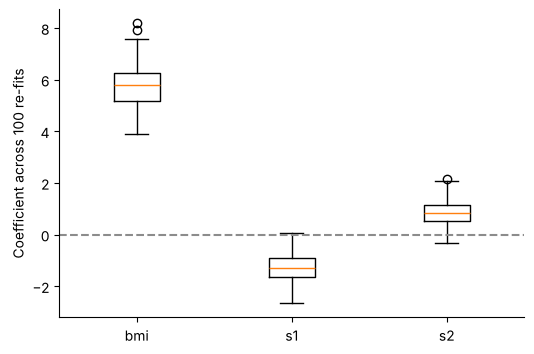

In [11]:
rng = np.random.default_rng(0)
boot = []
for _ in range(100):
    pick = rng.choice(len(X_train), len(X_train))
    m = LinearRegression().fit(X_train.iloc[pick], y_train.iloc[pick])
    boot.append(m.coef_)
boot = pd.DataFrame(boot, columns=X.columns)
plt.boxplot([boot["bmi"], boot["s1"], boot["s2"]], tick_labels=["bmi", "s1", "s2"])
plt.axhline(0, color=GRAY, linestyle="--")
plt.ylabel("Coefficient across 100 re-fits")
plt.show()

**Giải thích từng dòng**

- `rng = np.random.default_rng(0)`: (đã học) bộ phát số ngẫu nhiên.
- `for _ in range(100):`: (đã học) lặp 100 lần. Tên `_` là quy ước cho **biến vòng lặp mà ta không dùng đến**.
- `pick = rng.choice(len(X_train), len(X_train))`: (đã học `rng.choice` ở A2) bốc ngẫu nhiên **số dòng** bằng đúng cỡ tập học, **có hoàn lại** (một bệnh nhân có thể được bốc hai lần, một số khác không được bốc). Mỗi lần ta có một "phiên bản tập học hơi khác".
- `m = LinearRegression().fit(X_train.iloc[pick], y_train.iloc[pick])`: (đã học `iloc`) học lại trên mẫu bốc.
- `boot = pd.DataFrame(boot, columns=X.columns)`: gom 100 bộ hệ số thành bảng 100 dòng × 10 cột.
- `plt.boxplot([...], tick_labels=[...])`: (đã học `boxplot` ở A3) ba hộp, mỗi hộp là phân bố của một hệ số qua 100 lần học lại.

**Cách đọc**

- **Con số:** hệ số `bmi` dao động khoảng từ 4 đến 8 qua 100 lần (khá ổn, luôn dương). Hệ số `s1` dao động quanh **−1,3** (từ khoảng −2,7 đến 0), `s2` quanh **+0,8** (từ khoảng −0,4 đến +2,1). Chúng **ngược dấu nhau**, và `s2` thỉnh thoảng đổi cả dấu.
- **Bức tranh:** hộp của `bmi` nằm gọn ở một phía vạch 0: *đáng tin*. Hộp của `s1`, `s2` **đối nhau**: khi hệ số `s1` âm hơn thì `s2` dương hơn, như hai người kéo co. Máy chỉ biết tổng ảnh hưởng của cặp, còn cắt đôi cho từng người thì **tùy may rủi từng mẫu**.
- **Hệ quả:** đọc "`s1` làm giảm điểm, `s2` làm tăng điểm" là **kết luận sai**. Cả hai ít tác dụng riêng; chúng chỉ đang triệt tiêu nhau.

Kiểm chứng bằng cách **bỏ `s2`** và xem điều gì đổi:

In [12]:
no_s2 = [c for c in X.columns if c != "s2"]
reduced = LinearRegression().fit(X_train[no_s2], y_train)
before_after = pd.DataFrame({"with s2": full.coef_, "without s2": np.insert(reduced.coef_, list(X.columns).index("s2"), np.nan)}, index=X.columns).round(2)
print(before_after.loc[["s1", "s2", "s3", "bmi", "s5"]])
print("Test R2: with s2", round(full.score(X_test, y_test), 4), "| without s2", round(reduced.score(X_test[no_s2], y_test), 4))

     with s2  without s2
s1     -1.28       -0.44
s2      0.81         NaN
s3      0.60       -0.30
bmi     5.85        5.99
s5     67.11       44.92
Test R2: with s2 0.4526 | without s2 0.4526


**Giải thích từng dòng**

- `no_s2 = [c for c in X.columns if c != "s2"]`: (đã học list comprehension) danh sách mọi cột **trừ** `s2`; `!=` là "khác".
- `reduced = LinearRegression().fit(X_train[no_s2], y_train)`: học lại với chín cột.
- `np.insert(reduced.coef_, vị_trí, np.nan)`: **mới:** `np.insert(mảng, vị_trí, giá_trị)` chèn một giá trị vào mảng. Ta chèn ô trống (`np.nan`) vào đúng chỗ của `s2` để hai mảng hệ số (chín và mười số) **dài bằng nhau** và xếp cạnh nhau được. `list(X.columns).index("s2")` tìm vị trí của `s2` trong danh sách cột.
- `before_after.loc[["s1", "s2", "s3", "bmi", "s5"]]`: (đã học `.loc`) xem chỉ năm dòng cần quan sát.

**Cách đọc**

- **Con số:** bỏ `s2` thì hệ số `s1` đổi từ **−1,28 xuống −0,44**, hệ số `s3` thậm chí **đổi dấu** (từ +0,6 sang −0,3), hệ số `s5` tụt từ 67 xuống 45. R² thi gần như **không đổi** (0,4526 ở cả hai).
- **Bức tranh:** *dự đoán không đổi nhưng "câu chuyện" về từng hệ số thì đổi hẳn.* Hệ số phản ánh cách máy **chia công**, không phải sự thật về từng chỉ số. Khi các cột tương quan mạnh với nhau (**đa cộng tuyến**), chia công trở nên bấp bênh.
- **Hai việc khác nhau:**
  - Nếu mục tiêu là **đoán** (như chị Hạnh xếp hạng bệnh nhân), đa cộng tuyến **ít hại**: dự đoán vẫn ổn.
  - Nếu mục tiêu là **giải thích** ("chỉ số nào quan trọng"), đa cộng tuyến **làm hệ số không đáng tin**. Phải kiểm tra trước khi kể chuyện.

**Mang về chặng 5:** hai cột tương quan rất mạnh (đa cộng tuyến) làm hệ số bấp bênh, thậm chí đổi dấu, dù dự đoán ổn định. Muốn giải thích bằng hệ số thì phải kiểm tra tương quan giữa các cột trước.

## Chặng 6: Phán quyết bằng quyết định thật, chọn 10 người theo dõi

**Câu hỏi:** cuối cùng, mô hình nhiều cột giúp chị Hạnh chọn người **tốt hơn** không?

Như A3 đến A5: chị chọn 10 bệnh nhân trong tập thi để theo dõi sát. Thước đo là **điểm trung bình thật của 10 người được chọn** (càng cao càng bắt được người nặng).

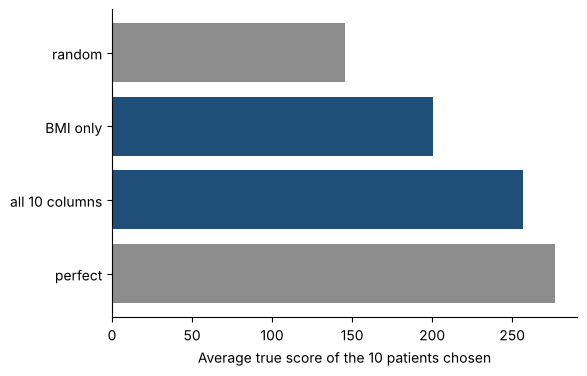

random            146.0
BMI only          200.0
all 10 columns    256.0
perfect           277.0
dtype: float64

In [13]:
def top10_mean(model, cols):
    best_ten = np.argsort(-model.predict(X_test[cols]))[:10]
    return y_test.to_numpy()[best_ten].mean()

bmi_only = LinearRegression().fit(X_train[["bmi"]], y_train)
picks = pd.Series({
    "random": y_test.mean(),
    "BMI only": top10_mean(bmi_only, ["bmi"]),
    "all 10 columns": top10_mean(full, list(X.columns)),
    "perfect": np.sort(y_test.to_numpy())[::-1][:10].mean(),
})
plt.barh(picks.index[::-1], picks.values[::-1], color=[GRAY, BLUE, BLUE, GRAY])
plt.xlabel("Average true score of the 10 patients chosen")
plt.show()
picks.round(0)

**Giải thích từng dòng**

- `def top10_mean(model, cols):`: (đã học `def`) hàm nhận một mô hình và danh sách cột nó dùng.
- `best_ten = np.argsort(-model.predict(X_test[cols]))[:10]`: (đã học `argsort`) dấu `-` đảo dấu để xếp **giảm dần**; `[:10]` lấy 10 vị trí đầu: 10 người máy cho điểm cao nhất.
- `return y_test.to_numpy()[best_ten].mean()`: điểm **thật** của 10 người đó, rồi lấy trung bình.
- `picks = pd.Series({...})`: (vừa học `pd.Series`) bốn con số: chọn ngẫu nhiên (trung bình tập thi), chọn theo mô hình BMI, chọn theo mô hình mười cột, và mức hoàn hảo (10 điểm cao nhất thật).
- `np.sort(y_test.to_numpy())[::-1][:10].mean()`: `[::-1]` **đảo ngược** mảng đã xếp tăng dần thành giảm dần.
- `plt.barh(picks.index[::-1], picks.values[::-1], color=[...])`: (đã học `barh`) đảo thứ tự để thanh "random" nằm dưới cùng; mỗi thanh một màu trong danh sách.

**Cách đọc**

- **Con số:** chọn ngẫu nhiên được khoảng **146**; mô hình BMI chọn được khoảng **200**; mô hình mười cột khoảng **256**; mức hoàn hảo khoảng **277**.
- **Bức tranh:** thanh "mười cột" **gần chạm** thanh hoàn hảo: khoảng cách đến mức hoàn hảo chỉ còn khoảng 20 điểm (so với khoảng 77 điểm của mô hình BMI). Ở thước đo của **quyết định thật**, việc thêm cột có lợi hơn rất nhiều so với con số R² có vẻ cho thấy (R² chỉ nhảy từ 0,23 lên 0,45).
- **Lưu ý thành thật:** chỉ có 89 bệnh nhân trong tập thi, và ta chọn 10 người, nên con số này dao động theo cách chia. Hình dáng "mười cột tốt hơn BMI" ổn định; con số cụ thể thì không.

## Phán quyết và bài học nghề

**Phán quyết cho chị Hạnh.** Cho máy xem nhiều chỉ số **giúp được**: MAE giảm từ 52 xuống khoảng 43, và quan trọng hơn, 10 người được chọn nặng hơn hẳn (256 thay vì 200 điểm). Nhưng hai ba chỉ số đầu (BMI, s5, bp) đã mang gần hết lợi ích. **Không nên** kết luận "chỉ số s1 làm giảm bệnh" hay "s2 làm tăng bệnh" từ hệ số; hai chỉ số này giẫm chân nhau.

**Bài học nghề.**

1. **Nhiều cột = mặt phẳng nhiều chiều.** Code không đổi; mỗi cột một độ dốc.
2. **Hệ số đọc là "giữ các cột khác không đổi".** Cột nhị phân (như `sex`) thì hệ số là độ chênh giữa hai nhóm.
3. **Đừng so hệ số thô giữa các cột khác đơn vị.** Quy về cùng thước (một độ lệch chuẩn), hoặc chuẩn hóa (B4).
4. **Thêm cột có hiệu suất giảm dần.** Đo bằng trung bình nhiều lần chia, trên tập thi.
5. **Đa cộng tuyến làm hệ số bấp bênh** dù dự đoán ổn. Muốn giải thích thì kiểm tra tương quan giữa các cột trước.
6. **Chấm bằng quyết định thật** (top 10) bên cạnh R² và MAE.

**Một điều thành thật:** mô hình mười cột vẫn chỉ giải thích khoảng 45% dao động. Hơn một nửa dao động vẫn chưa ai giải thích được bằng các chỉ số này. Đừng để con số "tốt hơn trước" che mất chuyện "vẫn chưa đủ tốt".

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Nhiều cột: mặt phẳng nhiều chiều y = a + b₁x₁ + ...; code không đổi; mỗi cột một độ dốc. |
| 2 | Dựng X bằng `drop(columns=...)`; dữ liệu mới phải cùng tên và cùng thứ tự cột (`feature_names_in_`). |
| 3 | Thêm cột: R² thi tăng rồi chững lại; đo bằng trung bình nhiều lần chia. |
| 4 | Hệ số đọc là "giữ các cột khác không đổi"; không so hệ số thô giữa các cột khác đơn vị. |
| 5 | Đa cộng tuyến làm hệ số bấp bênh dù dự đoán ổn; kiểm tra tương quan giữa các cột trước khi giải thích. |
| 6 | Chấm bằng quyết định thật: top 10 chọn được bao nhiêu điểm. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Tờ phiếu nhiều ô | đa biến (multiple regression) | `X` có nhiều cột |
| Mỗi cột một độ dốc | hệ số hồi quy | `model.coef_` |
| Tên cột máy đã học | tên đặc trưng | `model.feature_names_in_` |
| Hai cột gần như là một | đa cộng tuyến (multicollinearity) | `X.corr()` |
| Bốc lại mẫu có hoàn lại | bootstrap | `rng.choice(n, n)` |
| Hệ số kèm tên cột | chuỗi có nhãn | `pd.Series(coef_, index=X.columns)` |
| Tác động của một bước điển hình | hệ số nhân độ lệch chuẩn | `coefs * X.std()` |
| Tương quan từng cột với đáp án | tương quan với đáp án | `X.corrwith(y)` |

**Thử thách tự làm**

1. Ở chặng 3, đổi thứ tự cột: thay vì xếp theo tương quan, xếp **tăng dần** (cột yếu nhất trước). Bậc thang R² trông thế nào? Cột nào làm đường vọt lên?
2. Chỉ giữ ba cột `bmi`, `s5`, `bp` và huấn luyện. So MAE, R² thi và điểm trung bình top 10 với mô hình mười cột. Bạn có nên dừng ở ba cột không?
3. Kể chuyện với dữ liệu khác: dùng `load_linnerud(as_frame=True)` (20 người tập thể dục), chọn `Weight` làm đáp án, ba cột tập luyện làm đề. Đọc từng hệ số bằng lời đời thường, rồi kiểm tra tương quan giữa các cột đề.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích mô hình nhiều cột là mặt phẳng và vì sao code không đổi.
- [ ] Dựng X nhiều cột nhanh và biết quy tắc cùng tên, cùng thứ tự.
- [ ] Đọc hệ số bằng câu "giữ các cột khác không đổi".
- [ ] Biết vì sao không so hệ số thô giữa các cột khác đơn vị.
- [ ] Nhận ra và giải thích được đa cộng tuyến.
- [ ] Phân biệt dùng mô hình để **đoán** với dùng để **giải thích**.

## Phần thưởng (Tip pro): VIF: một con số để bắt đa cộng tuyến


Chặng 5 phải làm cả thí nghiệm bốc mẫu mới thấy `s1` và `s2` giẫm chân nhau. Có cách nhanh hơn: tính **VIF** (Variance Inflation Factor, hệ số phình phương sai) cho từng cột. Mẹo tính gọn: **VIF của mỗi cột nằm trên đường chéo của nghịch đảo ma trận tương quan**. Quy ước thường dùng: VIF trên 5 là cần chú ý, trên 10 là nghiêm trọng.

In [14]:
corr_matrix = X.corr().to_numpy()
vif = pd.Series(np.diag(np.linalg.inv(corr_matrix)), index=X.columns).round(1)
vif.sort_values(ascending=False)

s1     59.2
s2     39.2
s3     15.4
s5     10.1
s4      8.9
bp      1.5
bmi     1.5
s6      1.5
sex     1.3
age     1.2
dtype: float64

**Giải thích từng dòng**

- `corr_matrix = X.corr().to_numpy()`: (đã học `corr` ở A3) ma trận tương quan 10×10, đổi thành mảng numpy.
- `np.linalg.inv(corr_matrix)`: **nghịch đảo ma trận**: một phép toán đại số tuyến tính có sẵn trong numpy (`linalg` là *linear algebra*, đại số tuyến tính). Ta chỉ cần dùng, không cần hiểu cách tính.
- `np.diag(...)`: lấy **đường chéo** của ma trận (10 số, mỗi cột một số).
- `pd.Series(..., index=X.columns)`: (đã học) gắn tên cột để đọc.

**Cách đọc:** `s1` (khoảng **59**) và `s2` (khoảng **39**) vọt lên rất cao; `s3` (15), `s5` (10) và `s4` (9) ở mức đáng chú ý; các cột còn lại gần 1 đến 1,5 (sạch). Chỉ một dòng code đã chỉ ra đúng cặp sinh đôi ta mất cả chặng 5 để tìm.